<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Neural Networks with Keras

_Authors:_ Tim Book,  Justin Pounders (ATL), and Riley Dallas (ATX)

---


### Learning Objectives

- Describe the basic `keras` workflow.
- Train regression and classification neural networks using `keras`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import imdb, reuters

# Regression
---

`make_regression` is an excellent library for generating a random regression problem. This helps us focus on the model without having to worry about the dataset. 

In the cell below, we'll use `make_regression` to generate 10,000 samples using 20 features. We'll also go ahead and carry out our train-test-split and scaling.

In [2]:
X, y = make_regression(n_samples=10000, n_features=20, random_state=2022)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

In [3]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### Your first Neural Network!!
---

Next stop, [The Singularity](https://en.wikipedia.org/wiki/Technological_singularity)!

Creating a model in `keras` entails a few steps:
1. Create your network topology
2. Compile your model
3. Fit your model

We'll cover each step in the cells below.

### Create your network topology
---

We'll create a simple network with:
- an input layer
- one hidden layer. As a general rule, you should use `'relu'` as your activation function for all hidden layers.
- an output layer. 

For *all* regression problems, your output layer will be 1 neuron with *no* activation function. 

In [4]:
# Instantiate a model in the "sequential" style.
# This has nothing to do with the actual neural net itself,
# it's just that keras allows us to code them in a few different ways.
model = Sequential()
model.add(Dense(
    # How many neurons do you want in your first layer.
    32,
    # What is the shape of ONE input sample?
    input_shape=(20,),
    # What is the activation function for the output of this layer?
    activation='relu'
))
# The last layer is the output neuron - we only have one scalar output,
# so no need for an activation!
model.add(Dense(1))

In [5]:
# Model summary - what do we see?
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 32)                672       
_________________________________________________________________
dense_1 (Dense)              (None, 1)                 33        
Total params: 705
Trainable params: 705
Non-trainable params: 0
_________________________________________________________________


### Compile your model
---

Whenever you compile your model, you have to specify a few things: 
1. What [loss function](https://keras.io/losses/) to use (depends on if it's regression, classification, etc)
2. What optimizer to use (François Chollet, the author of Keras, says RMSProp is generally fine in all cases. Others disagree. Rarely ever matters.)
3. Optional: What additional [metrics](https://keras.io/metrics/) you'd like to monitor

In [6]:
model.compile(loss='mse', optimizer='rmsprop', metrics=['mae'])

### Fit your model
---

When fitting your model, you need to specify a few things:
1. The number of epochs = How many passes through the entire dataset to make. You want to go until your model performs well without overfitting.
2. Your batch size = How many training samples to use at each iteration of gradient descent. Always pick a number that is a power of 2 for GPU optimiation reasons.
3. Your validation data, which in this case is our test set. (Generally though, neural nets use a 3-way train-val-test split).

In [7]:
history = model.fit(
    X_train_sc,
    y_train,
    validation_data=(X_test_sc, y_test),
    epochs=10,
    batch_size=512
)

Epoch 1/10
15/15 [==============================] - 0s 10ms/step - loss: 34868.3594 - mae: 148.6280 - val_loss: 35028.2734 - val_mae: 150.1806
Epoch 2/10
15/15 [==============================] - 0s 3ms/step - loss: 34799.6953 - mae: 148.4823 - val_loss: 34964.8633 - val_mae: 150.0468
Epoch 3/10
15/15 [==============================] - 0s 3ms/step - loss: 34735.0234 - mae: 148.3452 - val_loss: 34897.3945 - val_mae: 149.9033
Epoch 4/10
15/15 [==============================] - 0s 3ms/step - loss: 34665.1953 - mae: 148.1962 - val_loss: 34824.5039 - val_mae: 149.7476
Epoch 5/10
15/15 [==============================] - 0s 3ms/step - loss: 34588.3203 - mae: 148.0320 - val_loss: 34743.1250 - val_mae: 149.5731
Epoch 6/10
15/15 [==============================] - 0s 3ms/step - loss: 34502.8359 - mae: 147.8496 - val_loss: 34653.1484 - val_mae: 149.3795
Epoch 7/10
15/15 [==============================] - 0s 3ms/step - loss: 34408.6953 - mae: 147.6472 - val_loss: 34554.6953 - val_mae: 149.1670
Epoch

### Model predictions
---

Your `keras` model has a `.predict()` method, similar to `sklearn`. Note the result here is a matrix rather than a vector.

In [8]:
model.predict(X_test_sc)

array([[4.5281787 ],
       [4.4442124 ],
       [5.543704  ],
       ...,
       [3.8932848 ],
       [2.5468678 ],
       [0.04445213]], dtype=float32)

### Model performance
---
We can actually see how our model performs over time.

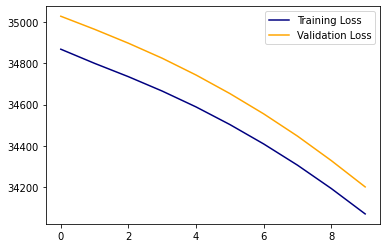

In [9]:
# It's still dropping after 10 epochs! Let's add more and see how low we can go.
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend()

# A More Interesting Example: Binary Classification with NLP!
---
The IMDB dataset is a set of 50,000 highly polarized movie reviews. We're predicting sentiment, where 0 = negative and 1 = positive sentiment.

In [10]:
(train_data, train_labels), (test_data, test_labels) = \
    imdb.load_data(num_words=10_000)

In [11]:
train_data[0][:10]

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65]

In [12]:
train_labels[0]

1

In [13]:
train_labels.mean()

0.5

In [14]:
# y_train = np.array(train_labels).astype('float')
# y_test = np.array(test_labels).astype('float')

In [15]:
# Decode data - I'll do this quickly now, but you should read this
# later and convince yourself this makes sense.
word_ix = imdb.get_word_index()
key_to_word = {v: k for k, v in word_ix.items()}
train_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in train_data
]
test_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in test_data
]

In [16]:
train_decoded[0]

" this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert  is an amazing actor and now the same being director  father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for  and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also  to the two little boy's that played the  of norman and paul they were just brilliant children are often left out of the  list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you think the

In [17]:
# (YOU) Count vectorize my data! (All default variables are ok)
cv = CountVectorizer()
X_train = cv.fit_transform(train_decoded).toarray()
X_test= cv.transform(test_decoded).toarray()

In [18]:
type(X_train)

numpy.ndarray

In [19]:
# (YOU) Build me a neural net with the following specs:
# - Two hidden layers each with 16 nodes and relu activation
# - One output layer... but what activation do we use here?
model = Sequential()
model.add(Dense(16, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [20]:
# Model summary - what's it look like?
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_2 (Dense)              (None, 16)                156352    
_________________________________________________________________
dense_3 (Dense)              (None, 16)                272       
_________________________________________________________________
dense_4 (Dense)              (None, 1)                 17        
Total params: 156,641
Trainable params: 156,641
Non-trainable params: 0
_________________________________________________________________


In [21]:
# Compile the model 
model.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [22]:
history = model.fit(
    X_train, train_labels,
    epochs=20,
    batch_size=512,
    validation_data=(X_test, test_labels),
    verbose=2
)

Epoch 1/20
49/49 - 2s - loss: 0.4736 - accuracy: 0.8000 - val_loss: 0.3776 - val_accuracy: 0.8609
Epoch 2/20
49/49 - 1s - loss: 0.2906 - accuracy: 0.8998 - val_loss: 0.3156 - val_accuracy: 0.8802
Epoch 3/20
49/49 - 1s - loss: 0.2222 - accuracy: 0.9215 - val_loss: 0.2924 - val_accuracy: 0.8869
Epoch 4/20
49/49 - 1s - loss: 0.1923 - accuracy: 0.9318 - val_loss: 0.3750 - val_accuracy: 0.8594
Epoch 5/20
49/49 - 1s - loss: 0.1641 - accuracy: 0.9417 - val_loss: 0.3256 - val_accuracy: 0.8773
Epoch 6/20
49/49 - 1s - loss: 0.1479 - accuracy: 0.9493 - val_loss: 0.3915 - val_accuracy: 0.8618
Epoch 7/20
49/49 - 1s - loss: 0.1284 - accuracy: 0.9554 - val_loss: 0.4260 - val_accuracy: 0.8573
Epoch 8/20
49/49 - 1s - loss: 0.1195 - accuracy: 0.9591 - val_loss: 0.3685 - val_accuracy: 0.8733
Epoch 9/20
49/49 - 1s - loss: 0.1086 - accuracy: 0.9632 - val_loss: 0.3906 - val_accuracy: 0.8694
Epoch 10/20
49/49 - 1s - loss: 0.0923 - accuracy: 0.9702 - val_loss: 0.4067 - val_accuracy: 0.8676
Epoch 11/20
49/49 -

In [23]:
model.evaluate(X_test, test_labels)

782/782 [==============================] - 1s 2ms/step - loss: 0.6963 - accuracy: 0.8521


[0.6962686777114868, 0.8520799875259399]

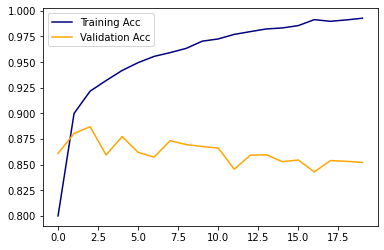

In [24]:
plt.plot(history.history['accuracy'], c='navy', label='Training Acc')
plt.plot(history.history['val_accuracy'], c='orange', label='Validation Acc')
plt.legend();

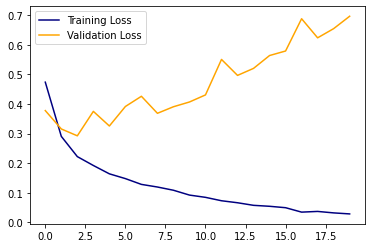

In [25]:
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend();

# If Time: Another one!
Let's try another, much bigger problem! This time we have Reuters news articles and 46 mutually exclusive topic labels.

In [26]:
(train_data, train_labels), (test_data, test_labels) = \
    reuters.load_data(num_words=10_000)

In [27]:
# Again, for the sake of time...
# Decode data - I'll do this quickly now, but you should read this
# later and convince yourself this makes sense.
word_ix = reuters.get_word_index()
key_to_word = {v: k for k, v in word_ix.items()}
train_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in train_data
]
test_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in test_data
]

cv = CountVectorizer()
X_train = cv.fit_transform(train_decoded).toarray()
X_test = cv.transform(test_decoded).toarray()

In [28]:
# (YOU): Fit me a new model with:
# - Two dense layers with 64 nodes in each (and what activation?)
# - One output layer... with how many output nodes? And what activation?
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(46, activation='softmax'))

In [29]:
# Summary
model.summary()

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_5 (Dense)              (None, 64)                618816    
_________________________________________________________________
dense_6 (Dense)              (None, 64)                4160      
_________________________________________________________________
dense_7 (Dense)              (None, 46)                2990      
Total params: 625,966
Trainable params: 625,966
Non-trainable params: 0
_________________________________________________________________


In [30]:
model.compile(
    optimizer='rmsprop',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
history = model.fit(
    X_train, train_labels,
    epochs=20,
    batch_size=512,
    validation_data=(X_test, test_labels),
    verbose=2
)

Epoch 1/20
18/18 - 1s - loss: 2.6673 - accuracy: 0.5305 - val_loss: 1.8012 - val_accuracy: 0.6990
Epoch 2/20
18/18 - 0s - loss: 1.4196 - accuracy: 0.7548 - val_loss: 1.3667 - val_accuracy: 0.7382
Epoch 3/20
18/18 - 0s - loss: 1.0216 - accuracy: 0.8128 - val_loss: 1.1663 - val_accuracy: 0.7680
Epoch 4/20
18/18 - 0s - loss: 0.7745 - accuracy: 0.8528 - val_loss: 1.1025 - val_accuracy: 0.7769
Epoch 5/20
18/18 - 0s - loss: 0.6049 - accuracy: 0.8866 - val_loss: 1.0299 - val_accuracy: 0.7921
Epoch 6/20
18/18 - 0s - loss: 0.4853 - accuracy: 0.9086 - val_loss: 1.0227 - val_accuracy: 0.7872
Epoch 7/20
18/18 - 0s - loss: 0.3976 - accuracy: 0.9201 - val_loss: 0.9816 - val_accuracy: 0.8037
Epoch 8/20
18/18 - 0s - loss: 0.3333 - accuracy: 0.9300 - val_loss: 1.0425 - val_accuracy: 0.7863
Epoch 9/20
18/18 - 0s - loss: 0.2880 - accuracy: 0.9390 - val_loss: 0.9900 - val_accuracy: 0.8090
Epoch 10/20
18/18 - 0s - loss: 0.2510 - accuracy: 0.9436 - val_loss: 1.0232 - val_accuracy: 0.8054
Epoch 11/20
18/18 -

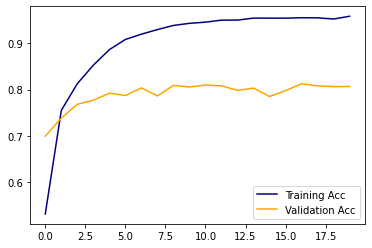

In [32]:
plt.plot(history.history['accuracy'], c='navy', label='Training Acc')
plt.plot(history.history['val_accuracy'], c='orange', label='Validation Acc')
plt.legend();

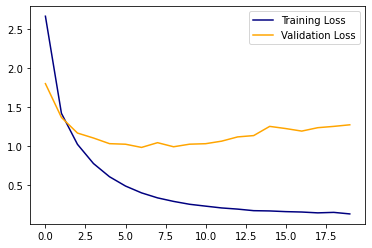

In [33]:
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend();